# Lecture 2 — Class Exercise
# Bar Charts: World Happiness Report 2023

---

> **Your task:** Create **2 polished bar charts** using the World Happiness Report dataset.  
> **Push to:** `week02/lecture02_exercise.ipynb` in **your own GitHub repo** before the end of class.

---

### Rules to keep in mind 💡
1. Every bar chart **must have a zero baseline** — no exceptions
2. Every chart **must have an insight title**, not a topic title
3. Aim for **professional quality** — clean background, readable font, no clutter
4. Horizontal bars for long category names

---


## Setup — Run this cell first


In [3]:
import pandas as pd
import numpy as np

# World Happiness Report 2023 — representative data
# Source: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2023

df = pd.read_csv('data/world_happiness_2023.csv')
df.columns = ['Country','Region','Happiness_Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']


print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
print(df.head())


Dataset: 63 countries, 9 columns
       Country                        Region  Happiness_Score     GDP  \
0      Finland                Western Europe            7.804  10.775   
1      Denmark                Western Europe            7.586  10.933   
2      Iceland                Western Europe            7.525  10.878   
3       Israel  Middle East and North Africa            7.473  10.527   
4  Netherlands                Western Europe            7.464  11.015   

   Social_Support  Life_Expectancy  Freedom  Generosity  Corruption  
0           0.954             71.9    0.949       0.142       0.179  
1           0.954             72.7    0.931       0.168       0.234  
2           0.983             72.5    0.961       0.260       0.150  
3           0.916             72.4    0.903       0.149       0.826  
4           0.939             72.4    0.879       0.240       0.296  


In [4]:

import plotly.express as px
import plotly.graph_objects as go

# Explore the dataset before you start
print("Regions in dataset:")
print(df['Region'].value_counts())
print("\nScore range:", df['Happiness_Score'].min(), "–", df['Happiness_Score'].max())
print("\nBottom 10 countries:")
print(df.nsmallest(10, 'Happiness_Score')[['Country','Region','Happiness_Score']])


Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range: 1.859 – 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

---
## Task 1 — Regional Comparison Bar Chart

**What to build:** A horizontal bar chart showing the **average happiness score by region**, sorted from highest to lowest.

**Requirements:**
- Horizontal orientation (category names are long)
- Sorted by score, descending (so the happiest region is at the top)
- Zero baseline on x-axis
- At least one design choice that goes beyond the Plotly default (colour, annotation, labels, etc.)
- An insight title that answers: *which region stands out and why does it matter?*

**Hint:** Use `df.groupby('Region')['Happiness_Score'].mean()` to compute the averages.


                         Region  Happiness_Score
5                    South Asia         3.618250
7            Sub-Saharan Africa         4.064714
3  Middle East and North Africa         4.943333
6                Southeast Asia         5.695250
2   Latin America and Caribbean         5.699000
1                     East Asia         5.966000
0    Central and Eastern Europe         6.338143
4         North America and ANZ         7.018250
8                Western Europe         7.085533


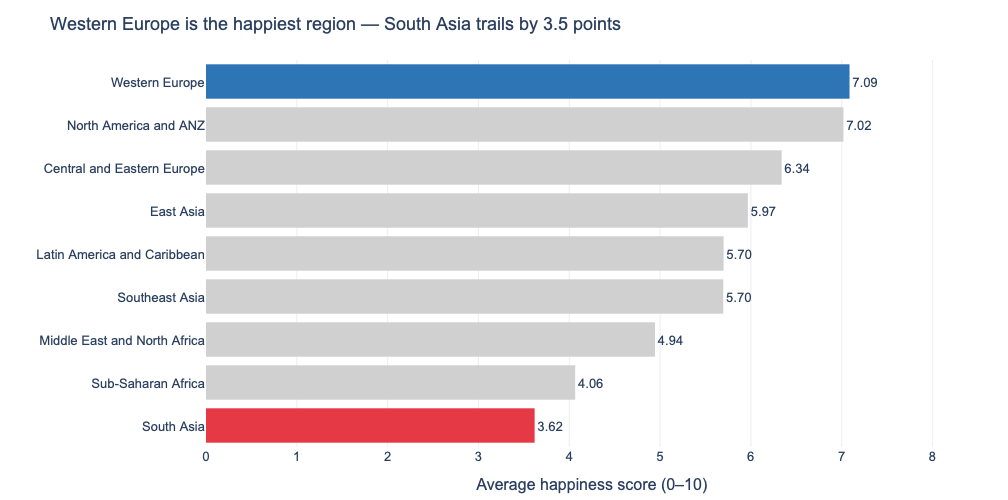

In [5]:
# Task 1: Regional comparison bar chart
# -------------------------------------

# Step 1: Compute average happiness score by region
region_avg = (df.groupby('Region')['Happiness_Score']
              .mean()
              .reset_index()
              .sort_values('Happiness_Score'))  # sort for horizontal bar
print(region_avg)

# Step 2: Build the chart
top_r = region_avg.iloc[-1]   # happiest region (last row after ascending sort)
bot_r = region_avg.iloc[0]    # least happy region (first row)
gap = top_r['Happiness_Score'] - bot_r['Happiness_Score']

region_avg['highlight'] = region_avg['Region'].map(
    lambda r: 'Top' if r == top_r['Region'] else ('Bottom' if r == bot_r['Region'] else 'Other')
)

fig = px.bar(
    region_avg,
    x='Happiness_Score', y='Region',
    orientation='h',
    color='highlight',
    color_discrete_map={'Top': '#2E75B6', 'Bottom': '#E63946', 'Other': '#D0D0D0'},
    text='Happiness_Score',
    title=f"{top_r['Region']} is the happiest region — {bot_r['Region']} trails by {gap:.1f} points",
    labels={'Happiness_Score': 'Average happiness score (0–10)', 'Region': ''},
    height=500
)
fig.update_traces(texttemplate='%{text:.2f}', textposition='outside', marker_line_width=0)
fig.update_yaxes(categoryorder='total ascending')
fig.update_layout(
    xaxis=dict(range=[0, 8.5], gridcolor='#EEEEEE'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    showlegend=False,
    margin=dict(l=10, r=30, t=60, b=40)
)
fig.show()


---
## Task 2 — Bottom vs. Top: A Contrast Story

**What to build:** A bar chart that highlights the **gap between the happiest and least happy countries**, focusing on a specific insight.

**Requirements:**
- Show the **top 8 AND bottom 8 countries** together (16 bars total)
- Use **colour** to distinguish the two groups (not Plotly's default rainbow)
- Add a **visual separator or annotation** that emphasises the gap
- Insight title that tells the story of the gap

**Hint:** Use `pd.concat([df.nlargest(8,'Happiness_Score'), df.nsmallest(8,'Happiness_Score')])` to get both groups.

**Stretch goal:** Add a vertical reference line showing the global average.


Global average: 5.81


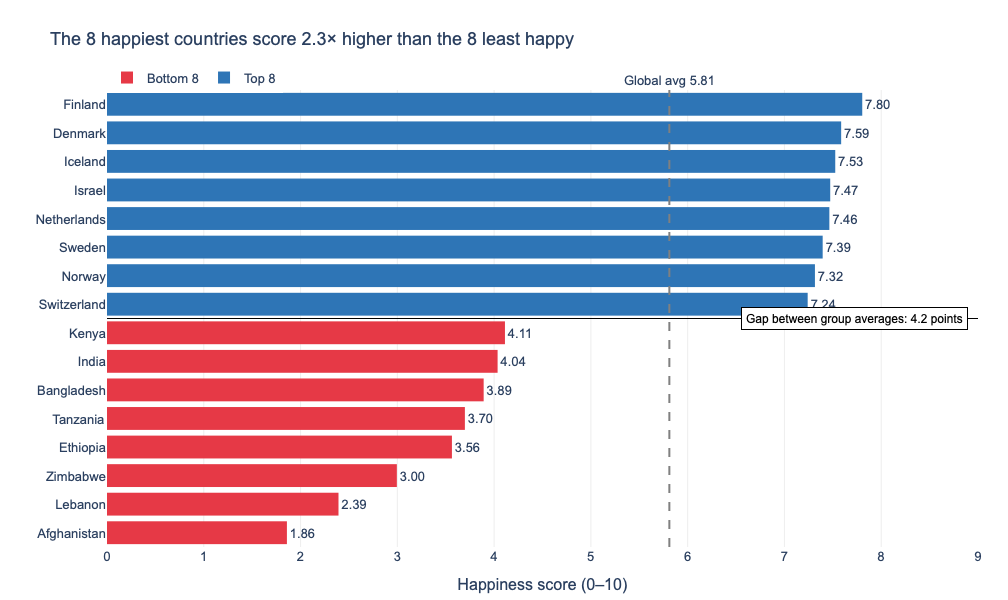

In [6]:
# Task 2: Top 8 vs. Bottom 8 contrast
# ------------------------------------

# Step 1: Get top and bottom countries
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'
bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()
print(f"Global average: {global_avg:.2f}")

# Step 2: Build the chart
top_mean = top8['Happiness_Score'].mean()
bot_mean = bottom8['Happiness_Score'].mean()
gap = top_mean - bot_mean

fig = px.bar(
    combined,
    x='Happiness_Score', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Top 8': '#2E75B6', 'Bottom 8': '#E63946'},
    text='Happiness_Score',
    title=f"The 8 happiest countries score {top_mean / bot_mean:.1f}× higher than the 8 least happy",
    labels={'Happiness_Score': 'Happiness score (0–10)', 'Country': '', 'Group': ''},
    height=600
)
fig.update_traces(texttemplate='%{text:.2f}', textposition='outside', marker_line_width=0)
fig.update_yaxes(categoryorder='total ascending')

# Separator line between the two groups (bottom 8 occupy positions 0–7, top 8 occupy 8–15)
fig.add_hline(y=7.5, line_color='black', line_width=1)

# Gap annotation sitting on the separator
fig.add_annotation(
    x=8.9, y=7.5, xanchor='right',
    text=f"Gap between group averages: {gap:.1f} points",
    showarrow=False,
    font=dict(size=12, color='black'),
    bgcolor='white', bordercolor='black', borderwidth=1, borderpad=4
)

# Stretch: global average reference line
fig.add_vline(
    x=global_avg, line_dash='dash', line_color='grey',
    annotation_text=f"Global avg {global_avg:.2f}", annotation_position='top'
)

fig.update_layout(
    xaxis=dict(range=[0, 9], gridcolor='#EEEEEE'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    legend=dict(orientation='h', y=1.06, x=0),
    margin=dict(l=10, r=30, t=90, b=40)
)
fig.show()


---
## Done? Stretch Goal

If you finish both tasks with time to spare, try this:

**Task 3 (stretch):** Build a **grouped bar chart** comparing 2 sub-factors (e.g. `GDP_per_capita` and `Freedom`) across the 5 most populated regions. Use colour meaningfully and write an insight title.

Regions to include: `'Western Europe'`, `'Latin America'`, `'East Asia'`, `'Sub-Saharan Africa'`, `'South Asia'`


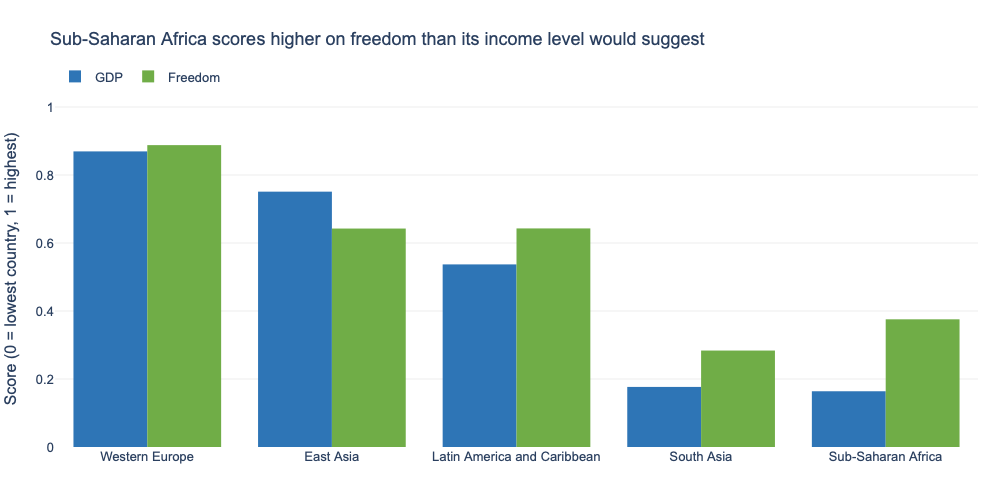

In [8]:
# Task 3 (stretch): grouped bar chart — GDP vs Freedom by region
# ---------------------------------------------------------------
# Note: the dataset uses 'Latin America and Caribbean', not 'Latin America'
regions = ['Western Europe', 'Latin America and Caribbean', 'East Asia',
           'Sub-Saharan Africa', 'South Asia']

# GDP (~7–11, log scale) and Freedom (0–1) are on different scales,
# so rescale both to 0–1 across ALL countries before comparing them
scaled = df.copy()
for col in ['GDP', 'Freedom']:
    scaled[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

reg = (scaled[scaled['Region'].isin(regions)]
       .groupby('Region')[['GDP', 'Freedom']]
       .mean()
       .reset_index()
       .sort_values('GDP', ascending=False))

# Region where freedom is highest relative to income -> insight title
reg['diff'] = reg['Freedom'] - reg['GDP']
standout = reg.loc[reg['diff'].idxmax(), 'Region']

long = reg.melt(id_vars='Region', value_vars=['GDP', 'Freedom'],
                var_name='Factor', value_name='Scaled score')

fig = px.bar(
    long,
    x='Region', y='Scaled score',
    color='Factor', barmode='group',
    color_discrete_map={'GDP': '#2E75B6', 'Freedom': '#70AD47'},
    title=f"{standout} scores higher on freedom than its income level would suggest",
    labels={'Scaled score': 'Score (0 = lowest country, 1 = highest)', 'Region': ''},
    height=500
)
fig.update_traces(marker_line_width=0)
fig.update_layout(
    yaxis=dict(range=[0, 1.05], gridcolor='#EEEEEE'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    legend=dict(orientation='h', y=1.08, x=0, title=''),
    margin=dict(l=10, r=30, t=90, b=40)
)
fig.show()
